in a reactor with excess A, the reaction A+B reaches equillibrium as product C. Initial concentrations are [A]=2.0,[b]=1.0 and [c]= 0mols. if x mol/l of c is formed, Kc=x/(2-x)(1-x), which rearranges to the quadratic equation being Kc*x^2-(3Kc+1)*x+2Kc=0. Write a python program that: 

 1 Reads Kc using input(), prints the data type of the raw input and of the converted value, and shows a clear message (no crash) if thr tet is not  a number of if Kc<=0  .

 2 find a,b,c the discriminant and both roots,

 3 selets the physically meaningful root (0<=x<=1),because B is limiting

 4 Print the equllibrium [A],[B],[C] and the conversion of the limiting reactant B=x/[B]*   (100%), 
 
 5 classfies the conversion using if/elif/else:>=70%"High" >=40%"moderate", otherwise"low"


In [1]:
import math

raw_kc = input("Enter Kc: ")
print("Raw input type:", type(raw_kc))

try:
    kc = float(raw_kc)
except ValueError:
    print("Invalid input: Kc must be a number.")
else:
    print("Converted value type:", type(kc))

    if not math.isfinite(kc) or kc <= 0:
        print("Invalid input: Kc must be a finite number greater than 0.")
    else:
        # Coefficients for Kc*x^2 - (3*Kc + 1)*x + 2*Kc = 0
        a = kc
        b = -(3 * kc + 1)
        c = 2 * kc

        discriminant = b**2 - 4 * a * c
        print(f"\nQuadratic coefficients: a = {a}, b = {b}, c = {c}")
        print(f"Discriminant: {discriminant}")

        sqrt_discriminant = math.sqrt(discriminant)

        # The roots have product 2. This form helps avoid loss of precision
        # when calculating the smaller, physically meaningful root.
        root_2 = (-b + sqrt_discriminant) / (2 * a)
        root_1 = 2 / root_2

        print(f"Root 1: {root_1}")
        print(f"Root 2: {root_2}")

        valid_roots = [root for root in (root_1, root_2) if 0 <= root <= 1]

        if not valid_roots:
            print("No physically meaningful root found in the range 0 <= x <= 1.")
        else:
            x = valid_roots[0]

            equilibrium_a = 2.0 - x
            equilibrium_b = 1.0 - x
            equilibrium_c = x

            # Conversion uses the initial concentration of limiting reactant B.
            conversion = (x / 1.0) * 100

            print("\nEquilibrium concentrations (mol/L):")
            print(f"[A] = {equilibrium_a:.3f}")
            print(f"[B] = {equilibrium_b:.3f}")
            print(f"[C] = {equilibrium_c:.3f}")
            print(f"B conversion = {conversion:.3f}%")

            if conversion >= 70:
                classification = "High"
            elif conversion >= 40:
                classification = "Moderate"
            else:
                classification = "Low"

            print("Conversion classification:", classification)

Raw input type: <class 'str'>
Converted value type: <class 'float'>

Quadratic coefficients: a = 4.0, b = -13.0, c = 8.0
Discriminant: 41.0
Root 1: 0.8246094703208939
Root 2: 2.425390529679106

Equilibrium concentrations (mol/L):
[A] = 1.175
[B] = 0.175
[C] = 0.825
B conversion = 82.461%
Conversion classification: High


Part A  Hydrogen peroxide decomposes in abatch reactor by a first order reaction,dC/dt=-Kc.Use the Euler method :C_oldDeltat. Take Cnot=1.5 mol/k=0.05 min inverse, deltat=2min. 

1 Using a for loop,simulate 20 minutes and print a table of Time(min),concentration(mol/L) and conversion(%)

2 Using math.exp(),calculate the exact value C_note^(-Kt) at 20 min and print the absolute error of the Euler reslts

3 Using a while loop, repat the simulation until conversion reaches 50% or time reaches 100 min.Print the time needed and the final concentration.

PartB reator tags such Reator -07/B-2026 are stored as text . Write a program that reads a tag, loops through each chacter and print the number of didits and the sum of the digits. shows a message for an empty tag and for atag with no digit. Test with Reactor-07/B-2026, an empty tag and ABCDEF

In [2]:
import math

# Given values
c0 = 1.5       # Initial concentration (mol/L)
k = 0.05       # Rate constant (min^-1)
dt = 2         # Time step (min)

# Simulate from 0 to 20 minutes using a for loop
time = 0
concentration = c0

print("Time (min)\tConcentration (mol/L)\tConversion (%)")
print(f"{time:>9}\t{concentration:>20.4f}\t{0.0:>14.2f}")

for step in range(1, 11):  # 10 steps of 2 minutes = 20 minutes
    concentration = concentration * (1 - k * dt)
    time = step * dt

    conversion = (c0 - concentration) / c0 * 100
    print(f"{time:>9}\t{concentration:>20.4f}\t{conversion:>14.2f}")

# Calculate the exact concentration at 20 minutes
exact_concentration = c0 * math.exp(-k * 20)

# Compare the Euler result at 20 minutes with the exact result
absolute_error = abs(concentration - exact_concentration)

print(f"\nExact concentration at 20 min: {exact_concentration:.4f} mol/L")
print(f"Absolute error at 20 min:      {absolute_error:.4f} mol/L")


# Continue using Euler's method until conversion reaches 50%
# or the time reaches 100 minutes.
time = 0
concentration = c0
conversion = 0

while conversion < 50 and time < 100:
    concentration = concentration * (1 - k * dt)
    time += dt
    conversion = (c0 - concentration) / c0 * 100

print("\nSimulation until 50% conversion or 100 min:")
print(f"Time needed: {time} min")
print(f"Final concentration: {concentration:.4f} mol/L")
print(f"Conversion: {conversion:.2f}%")

tag = input("Enter a reactor tag: ")

if tag == "":
    print("The tag is empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in tag:
        if character in "0123456789":
            digit_count += 1
            digit_sum += int(character)

    if digit_count == 0:
        print("The tag contains no digits.")
    else:
        print(f"Number of digits: {digit_count}")
        print(f"Sum of digits: {digit_sum}")

Time (min)	Concentration (mol/L)	Conversion (%)
        0	              1.5000	          0.00
        2	              1.3500	         10.00
        4	              1.2150	         19.00
        6	              1.0935	         27.10
        8	              0.9842	         34.39
       10	              0.8857	         40.95
       12	              0.7972	         46.86
       14	              0.7174	         52.17
       16	              0.6457	         56.95
       18	              0.5811	         61.26
       20	              0.5230	         65.13

Exact concentration at 20 min: 0.5518 mol/L
Absolute error at 20 min:      0.0288 mol/L

Simulation until 50% conversion or 100 min:
Time needed: 14 min
Final concentration: 0.7174 mol/L
Conversion: 52.17%
Number of digits: 6
Sum of digits: 17


Part A: A laboratry has n candidates catalysts and wants to test r of them together (order does not matter ). Write a recursive function factorial (n) (remember the base case fpr 0!) and a function combination (n,r)=n!/(r!(n-r)!) that uses it. Reject invalid input (negative values,r>n). Print the number of possibke catalyst sets for n=7,r=2 and shows the message for n=4,r=6
Part B : During a distillation ru, samples are taken at times= Fibonnaci numbers and a recursive function fib_reck(k) that returns the k-th fibonacci number(F0=,F1=1). For n=9, check that both functions agree and print the table Sample no, Fibonacci tag, Sampling time (min)

In [2]:
def factorial(n):
    if not isinstance(n, int) or isinstance(n, bool) or n < 0:
        raise ValueError("n must be a non-negative integer")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if (not isinstance(n, int) or isinstance(n, bool)
            or not isinstance(r, int) or isinstance(r, bool)):
        raise ValueError("n and r must be integers")
    if n < 0 or r < 0 or r > n:
        raise ValueError("Require n >= 0 and 0 <= r <= n")

    return factorial(n) // (factorial(r) * factorial(n - r))


def fib_iterative(n):
    if not isinstance(n, int) or isinstance(n, bool) or n < 0:
        raise ValueError("n must be a non-negative integer")

    values = []
    a, b = 0, 1
    for _ in range(n):
        values.append(a)
        a, b = b, a + b
    return values


def fib_reck(k):
    if not isinstance(k, int) or isinstance(k, bool) or k < 0:
        raise ValueError("k must be a non-negative integer")
    if k < 2:
        return k
    return fib_reck(k - 1) + fib_reck(k - 2)


# Part A
print(f"Number of catalyst sets for n=7, r=2: {combination(7, 2)}")

try:
    combination(4, 6)
except ValueError as error:
    print(f"Invalid input for n=4, r=6: {error}")

# Part B
n = 9
iterative_values = fib_iterative(n)
recursive_values = [fib_reck(k) for k in range(n)]

print(f"\nBoth Fibonacci functions agree for n={n}: "
      f"{iterative_values == recursive_values}")
print("Sample no\tFibonacci tag\tSampling time (min)")

for sample_no, (k, time_min) in enumerate(
        zip(range(n), iterative_values), start=1):
    print(f"{sample_no}\t\tF{k}={time_min}\t\t{time_min}")

Number of catalyst sets for n=7, r=2: 21
Invalid input for n=4, r=6: Require n >= 0 and 0 <= r <= n

Both Fibonacci functions agree for n=9: True
Sample no	Fibonacci tag	Sampling time (min)
1		F0=0		0
2		F1=1		1
3		F2=1		1
4		F3=2		2
5		F4=3		3
6		F5=5		5
7		F6=8		8
8		F7=13		13
9		F8=21		21


PART A: decompostion of hydrogen peroxide was studied with two catalyst loadings. The concentration (mol/L) was recorded:

time_min           Run1_mol_L(low loading)       Run2_mol_l(high loading)

  0                     1.20                         1.20
  10                    0.98                         0.80
  20                    0.80                          0.54
  30                    0.66                          0.36 
  40                    0.54                          0.24
  50                    0.44                          0.16

1 Create a Data Frame from the table.Save it as Kinetic.csv without an index coloum and as kinetics.json. Read csv back and print its shape and data types.

2 Print the means and standard deviation of Run1 and Run 2, and state which run shows more variation. 

3 Plot both runs on one graph with time on x-axis and a title,axis labels with units,a legend and a grid. 

4 Context: Carbon dioxide is slowly compressed in a piston-cylinder at constant temperature 

partB: use the following pressure-volume dats to create a scatter plot.Calculate K as the mean of P*V and draw the reference curve P=k/V on the same graph add a tilte axixs labele with units and a legend. 
 
 Volume_L         1        2        3         4        5 
 pressure_bar    3.02      1.49    1.01      0.76     0.59

CSV shape: (6, 3)

CSV data types:
time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object

Run1_mol_L: mean = 0.770 mol/L, standard deviation = 0.284 mol/L

Run2_mol_L: mean = 0.550 mol/L, standard deviation = 0.392 mol/L

Run 2 shows more variation.


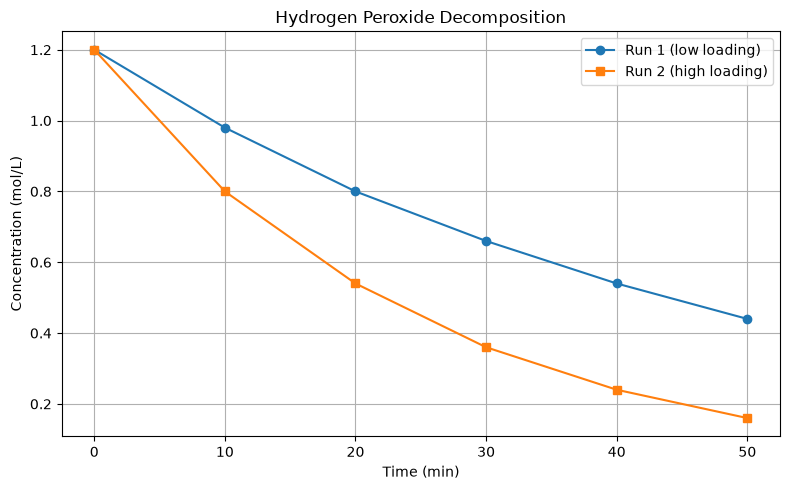


Mean K = 3.004 bar·L


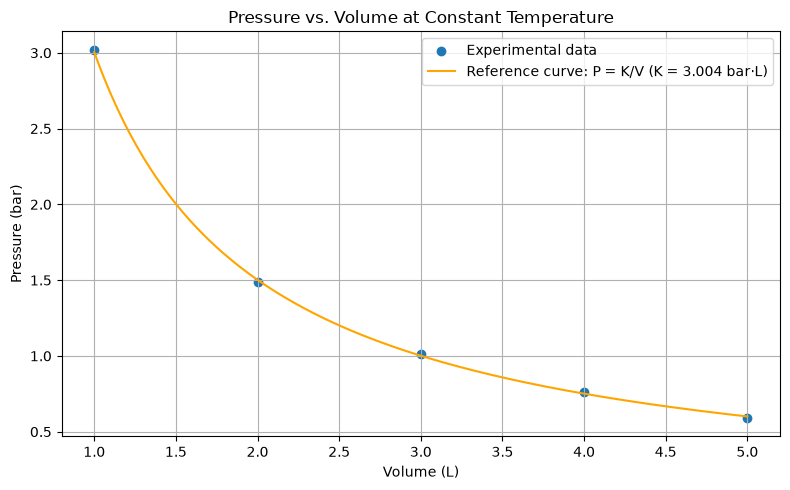

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Part A: Kinetics data
kinetics_df = pd.DataFrame({
    "time_min": [0, 10, 20, 30, 40, 50],
    "Run1_mol_L": [1.20, 0.98, 0.80, 0.66, 0.54, 0.44],
    "Run2_mol_L": [1.20, 0.80, 0.54, 0.36, 0.24, 0.16],
})

# Save data, then read the CSV back
kinetics_df.to_csv("Kinetic.csv", index=False)
kinetics_df.to_json("kinetics.json", orient="records", indent=2)

kinetics_from_csv = pd.read_csv("Kinetic.csv")
print("CSV shape:", kinetics_from_csv.shape)
print("\nCSV data types:")
print(kinetics_from_csv.dtypes)

# Print summary statistics and compare variation
for column in ["Run1_mol_L", "Run2_mol_L"]:
    print(
        f"\n{column}: mean = {kinetics_from_csv[column].mean():.3f} mol/L, "
        f"standard deviation = {kinetics_from_csv[column].std():.3f} mol/L"
    )

if kinetics_from_csv["Run1_mol_L"].std() > kinetics_from_csv["Run2_mol_L"].std():
    print("\nRun 1 shows more variation.")
else:
    print("\nRun 2 shows more variation.")

# Plot both catalyst loadings
plt.figure(figsize=(8, 5))
plt.plot(kinetics_df["time_min"], kinetics_df["Run1_mol_L"],
         marker="o", label="Run 1 (low loading)")
plt.plot(kinetics_df["time_min"], kinetics_df["Run2_mol_L"],
         marker="s", label="Run 2 (high loading)")
plt.title("Hydrogen Peroxide Decomposition")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Part B: Pressure-volume data
pv_df = pd.DataFrame({
    "Volume_L": [1, 2, 3, 4, 5],
    "Pressure_bar": [3.02, 1.49, 1.01, 0.76, 0.59],
})

pv_df["PV_bar_L"] = pv_df["Volume_L"] * pv_df["Pressure_bar"]
k = pv_df["PV_bar_L"].mean()
print(f"\nMean K = {k:.3f} bar·L")

# Scatter experimental measurements and overlay P = K/V
volume_curve = np.linspace(pv_df["Volume_L"].min(), pv_df["Volume_L"].max(), 200)
pressure_curve = k / volume_curve

plt.figure(figsize=(8, 5))
plt.scatter(pv_df["Volume_L"], pv_df["Pressure_bar"],
            label="Experimental data")
plt.plot(volume_curve, pressure_curve, color="orange",
         label=f"Reference curve: P = K/V (K = {k:.3f} bar·L)")
plt.title("Pressure vs. Volume at Constant Temperature")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()